# RQ3 Combined Feature-Importance and Monotonicity Regularization

This notebook studies whether two interpretability-driven priors can be imposed
simultaneously in next-day maximum temperature prediction:

1. a **feature-importance prior** on the global gate vector, and
2. a **monotonicity prior** on selected weather features.

## Goal

Train models with the objective

$$
L = L_{\text{task}} + \lambda_{\text{feat}} L_{\text{feat}} + \lambda_{\text{mono}} L_{\text{mono}},
$$

where:

- $L_{\text{task}}$ is the standard regression loss,
- $L_{\text{feat}}$ encourages the learned gate vector to match an expert feature-importance pseudo-label vector,
- $L_{\text{mono}}$ encourages the model to satisfy selected local monotonic relations,
- $\lambda_{\text{feat}}$ controls feature-prior strength,
- and $\lambda_{\text{mono}}$ controls monotonicity-prior strength.

## Inputs from earlier notebooks

This notebook combines outputs from the earlier experiments:

- **Notebook 05**: main feature-importance sweep,
- **Notebook 07**: monotonicity audit and selected local pair sets,
- **Notebook 08**: main monotonicity-regularized training sweep.

## Main questions

1. Can a model satisfy both priors at the same time?
2. How does combined regularization affect predictive performance?
3. Does the combined model improve both:
   - gate alignment to the expert feature prior, and
   - monotonicity diagnostics on the selected constrained features?
4. Is the best combined setting better than feature-only or monotonicity-only regularization?

## Scope

This notebook is intended as the main **RQ3 combined experiment**.

It is not primarily trying to produce the lowest possible RMSE. Instead, it asks
whether multiple interpretability priors can be integrated into training in a
compatible and practically useful way.

In [63]:
# Cell 1 - Imports and notebook setup

from pathlib import Path
import copy
import json
import random
import warnings

from typing import Any, cast

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

from IPython.display import display

from src.models import GatedMLRegressor
from src.training import (
    DEFAULT_TRAIN_CONFIG,
    TrainConfig,
    eval_loader_reg,
    make_standard_experiment_data,
)
from src.pseudolabels import make_feature_importance_z
from src.alignment import compute_alignment_metrics
from src.monotonicity import (
    combined_monotonicity_loss,
    compute_gradient_sign_audit,
    load_chosen_pair_artifacts,
    load_training_spec,
    make_counterfactual_sweep_df,
    make_pair_index_dict_from_manifest,
    make_sign_dict,
    pairwise_metrics_from_predictions,
    predict_numpy,
    select_representative_rows,
)

try:
    from scipy.stats import ConstantInputWarning
    warnings.filterwarnings("ignore", category=ConstantInputWarning)
except Exception:
    pass

sns.set_theme(style="whitegrid", context="talk")
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 180)

PROJECT_ROOT = Path("..").resolve()
RESULTS_ROOT = PROJECT_ROOT / "results"

BASELINE_DIR = RESULTS_ROOT / "baseline"
FEATURE_MAIN_DIR = RESULTS_ROOT / "feature_importance_basic" / "sweep_basic"
MONO_AUDIT_DIR = RESULTS_ROOT / "monotonicity_audit"
MONO_MAIN_DIR = RESULTS_ROOT / "monotonicity_training" / "sweep_main"
COMBINED_DIR = RESULTS_ROOT / "combined_regularization" / "sweep_main"

device = "cuda" if torch.cuda.is_available() else "cpu"

# Optional context tables loaded later if present
baseline_metrics_df = pd.DataFrame()
feature_main_summary_df = pd.DataFrame()
mono_main_summary_df = pd.DataFrame()

# Placeholders for downstream cells
combined_sweep_df = pd.DataFrame()
combined_history_df = pd.DataFrame()
agg_df = pd.DataFrame()
summary_table = pd.DataFrame()
family_best_df = pd.DataFrame()
family_best_comparison_df = pd.DataFrame()
family_mono_df = pd.DataFrame()
external_context_df = pd.DataFrame()
gate_profile_df = pd.DataFrame()
selected_model_manifest_df = pd.DataFrame()
selected_model_store: dict[tuple[float, float], GatedMLRegressor] = {}
counterfactual_summary_df = pd.DataFrame()
rep_rows = pd.DataFrame()
plot_families: list[str] = []
models_for_plots: dict[str, GatedMLRegressor] = {}
plot_labels: dict[str, str] = {}

print("Project root:", PROJECT_ROOT)
print("Results root:", RESULTS_ROOT)
print("Baseline dir:", BASELINE_DIR)
print("Feature sweep dir:", FEATURE_MAIN_DIR)
print("Monotonicity audit dir:", MONO_AUDIT_DIR)
print("Monotonicity main dir:", MONO_MAIN_DIR)
print("Combined results dir:", COMBINED_DIR)
print("Using device:", device)

Project root: <project root>
Results root: <project root>/results
Baseline dir: <project root>/results/baseline
Feature sweep dir: <project root>/results/feature_importance_basic/sweep_basic
Monotonicity audit dir: <project root>/results/monotonicity_audit
Monotonicity main dir: <project root>/results/monotonicity_training/sweep_main
Combined results dir: <project root>/results/combined_regularization/sweep_main
Using device: cuda


In [64]:
# Cell 1a - Execution mode

RUN_TRAINING = False
LOAD_SELECTED_MODELS = True

In [65]:
# Cell 1b - Cache loading utilities

def read_csv_if_exists(path: Path) -> pd.DataFrame:
    if path.exists():
        return pd.read_csv(path)
    print(f"[Missing] {path}")
    return pd.DataFrame()


def read_json_if_exists(path: Path):
    if path.exists():
        with open(path, "r") as fh:
            return json.load(fh)
    print(f"[Missing] {path}")
    return None


def require_file(path: Path) -> Path:
    assert path.exists(), f"Required file not found: {path}"
    return path

In [66]:
# Cell 2 - Load data and required saved artefacts

config = TrainConfig(
    lr=DEFAULT_TRAIN_CONFIG.lr,
    batch_size=DEFAULT_TRAIN_CONFIG.batch_size,
    eval_batch_size=DEFAULT_TRAIN_CONFIG.eval_batch_size,
    num_epochs=80,
    weight_decay=DEFAULT_TRAIN_CONFIG.weight_decay,
    early_stopping_patience=10,
    early_stopping_min_delta=0.0,
)

data = make_standard_experiment_data(PROJECT_ROOT, config)

feature_cols = data.feature_cols
train_loader = data.train_loader
val_loader = data.val_loader
test_loader = data.test_loader

training_spec_path = MONO_AUDIT_DIR / "training_spec_main.csv"
manifest_path = MONO_AUDIT_DIR / "chosen_pairs_manifest.csv"

assert training_spec_path.exists(), f"Missing {training_spec_path}. Run notebook 07 first."
assert manifest_path.exists(), f"Missing {manifest_path}. Run notebook 07 first."

manifest_df, pair_idx_store = load_chosen_pair_artifacts(MONO_AUDIT_DIR)
training_spec_df = load_training_spec(MONO_AUDIT_DIR, name="training_spec_main")

constrained_features = training_spec_df["feature"].astype(str).tolist()
sign_dict = make_sign_dict(training_spec_df)

assert len(constrained_features) > 0, (
    "training_spec_main.csv is empty. "
    "Revisit notebook 07 and ensure at least one monotonic feature was kept."
)

train_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="train",
    features=constrained_features,
)
val_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="val",
    features=constrained_features,
)
test_pair_index_dict = make_pair_index_dict_from_manifest(
    manifest_df,
    pair_idx_store,
    split="test",
    features=constrained_features,
)

# Optional context artefacts from earlier notebooks
baseline_metrics_path = BASELINE_DIR / "metrics.csv"
feature_main_summary_path = FEATURE_MAIN_DIR / "sweep_summary.csv"
mono_main_summary_path = MONO_MAIN_DIR / "sweep_summary.csv"

if baseline_metrics_path.exists():
    baseline_metrics_df = pd.read_csv(baseline_metrics_path)
else:
    print(f"[Optional] baseline metrics not found at {baseline_metrics_path}")

if feature_main_summary_path.exists():
    feature_main_summary_df = pd.read_csv(feature_main_summary_path)
else:
    print(f"[Optional] feature main summary not found at {feature_main_summary_path}")

if mono_main_summary_path.exists():
    mono_main_summary_df = pd.read_csv(mono_main_summary_path)
else:
    print(f"[Optional] monotonicity main summary not found at {mono_main_summary_path}")

print("Train/val/test sizes:", len(data.train_df), len(data.val_df), len(data.test_df))
print("Feature columns:", feature_cols)
print("Constrained features:", constrained_features)
print("Sign dict:", sign_dict)

print("\nMain monotonicity training spec:")
display(training_spec_df.round(4))

print("\nChosen-pair manifest overview:")
display(
    manifest_df[["split", "feature", "setting", "n_pairs"]]
    .sort_values(["feature", "split"])
    .reset_index(drop=True)
)

Train/val/test sizes: 2556 547 549
Feature columns: ['tmin', 'tavg', 'tmax', 'prcp', 'dayofyear_sin', 'dayofyear_cos', 'rand_noise']
Constrained features: ['tavg', 'tmax']
Sign dict: {'tavg': 1, 'tmax': 1}

Main monotonicity training spec:


,feature,direction,sign,chosen_setting,chosen_train_n_pairs,train_label_violation_rate,test_label_violation_rate,test_baseline_violation_rate,test_grad_violation_rate,confidence,rationale,notes
0,tavg,nondecreasing,1,local_knn_strict,340.0,0.1353,0.1298,0.0000,0.0000,high,Warmer recent average temperature should usual...,baseline is already more monotone than labels ...
1,tmax,nondecreasing,1,local_knn_medium,5113.0,0.2501,0.2335,0.0078,0.0018,medium,Warmer recent maximum temperature should usual...,baseline is already more monotone than labels ...



Chosen-pair manifest overview:


,split,feature,setting,n_pairs
0,test,prcp,local_knn_loose,3486
1,train,prcp,local_knn_loose,15610
2,val,prcp,local_knn_loose,3268
3,test,tavg,local_knn_strict,131
4,train,tavg,local_knn_strict,340
5,val,tavg,local_knn_strict,128
6,test,tmax,local_knn_medium,1533
7,train,tmax,local_knn_medium,5113
8,val,tmax,local_knn_medium,1634
9,test,tmin,local_knn_loose,3956


In [67]:
# Cell 3 - Define the expert feature-importance prior and inspect pair counts

z_np = make_feature_importance_z(feature_cols).astype(np.float32)
z_t = torch.from_numpy(z_np)

z_table = pd.DataFrame([z_np], columns=feature_cols, index=["expert_z"])

pair_count_rows = []
for split_name, pair_dict in [
    ("train", train_pair_index_dict),
    ("val", val_pair_index_dict),
    ("test", test_pair_index_dict),
]:
    for feature in constrained_features:
        pair_count_rows.append(
            {
                "split": split_name,
                "feature": feature,
                "n_pairs": int(len(pair_dict.get(feature, np.empty((0, 2), dtype=np.int64)))),
            }
        )

pair_count_df = pd.DataFrame(pair_count_rows)

print("Expert feature-importance pseudo-label vector:")
display(z_table.round(3))

print("Chosen monotonicity pair counts:")
display(pair_count_df)



Expert feature-importance pseudo-label vector:


,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
expert_z,0.7,1.0,1.0,0.4,0.3,0.3,0.0


Chosen monotonicity pair counts:


,split,feature,n_pairs
0,train,tavg,340
1,train,tmax,5113
2,val,tavg,128
3,val,tmax,1634
4,test,tavg,131
5,test,tmax,1533


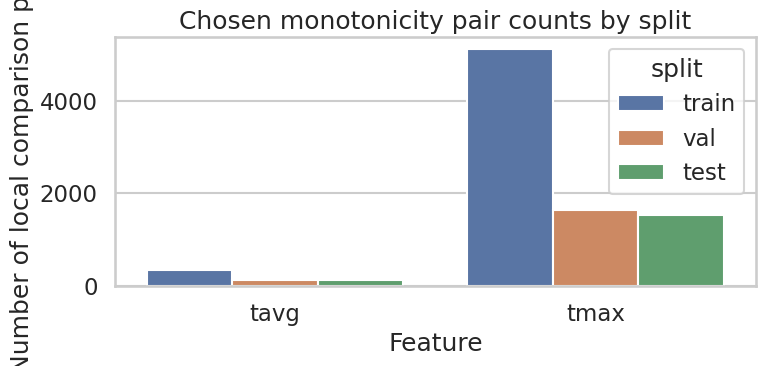

In [68]:
# Cell 3a - Chosen monotonicity pair counts by split (plot)
plt.figure(figsize=(8, 4))
sns.barplot(data=pair_count_df, x="feature", y="n_pairs", hue="split")
plt.title("Chosen monotonicity pair counts by split")
plt.xlabel("Feature")
plt.ylabel("Number of local comparison pairs")
plt.tight_layout()
plt.savefig("../docs/figures/ch5_rq3_pair_counts.pdf", dpi=300, bbox_inches="tight")
plt.show()

## Training objective and evaluation

The combined objective is

$$
L = L_{\text{task}} + \lambda_{\text{feat}} L_{\text{feat}} + \lambda_{\text{mono}} L_{\text{mono}}.
$$

### Task loss

The predictive loss is the mean squared error:

$$
L_{\text{task}} = \frac{1}{N}\sum_{i=1}^N \bigl(\hat y_i - y_i\bigr)^2.
$$

### Feature-importance regularization

For the gated model, the learned gate vector is $g \in (0,1)^d$. The
feature-prior loss is

$$
L_{\text{feat}} = \frac{1}{d}\sum_{j=1}^d (g_j - z_j)^2,
$$

where $z$ is the expert pseudo-label vector.

### Monotonicity regularization

For each constrained feature, notebook 07 selected local comparison pairs.
For each pair $(i,k)$, the desired condition is

$$
s \bigl(f(\mathbf{x}^{(i)}) - f(\mathbf{x}^{(k)})\bigr) \ge 0,
$$

where $s \in \{+1,-1\}$ encodes the monotonic direction.

The hinge-style penalty is

$$
\max\bigl(0,\,- s (f(\mathbf{x}^{(i)}) - f(\mathbf{x}^{(k)}))\bigr).
$$

### Main evaluation metrics

This notebook reports:

- predictive metrics:
  - MSE
  - RMSE
  - MAE

- feature-prior alignment metrics:
  - gate L2 distance to $z$
  - gate cosine similarity to $z$
  - gate Spearman rank correlation to $z$

- monotonicity metrics:
  - pairwise violation rate
  - mean hinge violation
  - gradient-sign violation rate

In [69]:
# Cell 4 - Experiment settings

# Compact but informative grid:
# - lambda_feat spans no feature prior, moderate prior, strong prior
# - lambda_mono spans no monotonicity prior, moderate prior, stronger prior
lambda_feat_values = [0.0, 1.0, 10.0, 100.0, 1000.0]
lambda_mono_values = [0.0, 1.0, 10.0, 100.0, 1000.0]
seeds = [0, 1, 2, 3, 4]

mono_margin = 0.0
mono_reduction = "mean_over_features"
max_pairs_per_feature_train = 1024
max_pairs_per_feature_eval = None

# Store exact trained models for one seed so we can make family-best qualitative plots
selected_seed_for_store = 0

family_order = ["gated_erm", "feature_only", "mono_only", "combined"]


def model_family_label(lambda_feat: float, lambda_mono: float) -> str:
    if lambda_feat == 0.0 and lambda_mono == 0.0:
        return "gated_erm"
    if lambda_feat > 0.0 and lambda_mono == 0.0:
        return "feature_only"
    if lambda_feat == 0.0 and lambda_mono > 0.0:
        return "mono_only"
    return "combined"


print("lambda_feat_values:", lambda_feat_values)
print("lambda_mono_values:", lambda_mono_values)
print("seeds:", seeds)
print("mono_margin:", mono_margin)
print("mono_reduction:", mono_reduction)
print("max_pairs_per_feature_train:", max_pairs_per_feature_train)
print("max_pairs_per_feature_eval:", max_pairs_per_feature_eval)
print("selected_seed_for_store:", selected_seed_for_store)

lambda_feat_values: [0.0, 1.0, 10.0, 100.0, 1000.0]
lambda_mono_values: [0.0, 1.0, 10.0, 100.0, 1000.0]
seeds: [0, 1, 2, 3, 4]
mono_margin: 0.0
mono_reduction: mean_over_features
max_pairs_per_feature_train: 1024
max_pairs_per_feature_eval: None
selected_seed_for_store: 0


In [70]:
# Cell 5 - Helper functions

class SimpleEarlyStopper:
    def __init__(self, patience: int, min_delta: float = 0.0) -> None:
        self.patience = patience
        self.min_delta = min_delta
        self.best_value = float("inf")
        self.num_bad_epochs = 0
        self.best_state: dict[str, torch.Tensor] | None = None

    def step(self, value: float, model: nn.Module) -> bool:
        if value + self.min_delta < self.best_value:
            self.best_value = value
            self.num_bad_epochs = 0
            self.best_state = copy.deepcopy(model.state_dict())
            return False

        self.num_bad_epochs += 1
        return self.num_bad_epochs >= self.patience

    def restore_best(self, model: nn.Module) -> None:
        if self.best_state is not None:
            model.load_state_dict(self.best_state)


def should_log(epoch: int, num_epochs: int) -> bool:
    return (epoch + 1) == 1 or (epoch + 1) % 10 == 0 or (epoch + 1) == num_epochs


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def instantiate_model(input_dim: int) -> GatedMLRegressor:
    return GatedMLRegressor(
        input_dim=input_dim,
        hidden_dims=(64, 64),
        dropout=0.0,
    )


def append_gate_history(
    row: dict[str, float],
    model: GatedMLRegressor,
    gate_names: list[str] | None = None,
) -> None:
    g_np = model.g.detach().cpu().numpy().astype(np.float64)
    if gate_names is None:
        gate_names = [str(j) for j in range(len(g_np))]
    for name, value in zip(gate_names, g_np):
        row[f"g_{name}"] = float(value)


def prefix_dict(d: dict[str, float], prefix: str) -> dict[str, float]:
    return {f"{prefix}_{k}": float(v) for k, v in d.items()}


def safe_mean(values: list[float]) -> float:
    if len(values) == 0:
        return float("nan")
    return float(np.mean(values))


def scalar_float(x: object) -> float:
    return float(cast(Any, x))


def row_float(row: pd.Series, key: str) -> float:
    return scalar_float(row.at[key])


def argmin_pos(df: pd.DataFrame, col: str) -> int:
    values = df[col].to_numpy(dtype=np.float64)
    return int(np.argmin(values))


def iloc_series(df: pd.DataFrame, pos: int) -> pd.Series:
    return cast(pd.Series, df.iloc[pos])


def gate_alignment_record(
    model: GatedMLRegressor,
    z_np: np.ndarray,
    *,
    g_init: np.ndarray | None = None,
    feature_cols: list[str] | None = None,
) -> dict[str, float]:
    g_final = model.g.detach().cpu().numpy().astype(np.float64)
    z64 = np.asarray(z_np, dtype=np.float64).ravel()

    final_align = compute_alignment_metrics(g_final, z64)

    out: dict[str, float] = {
        "gate_l2_final": float(final_align.l2_distance),
        "gate_cos_final": float(final_align.cosine_similarity),
        "gate_spearman_final": float(final_align.spearman_rank_corr),
        "feat_loss_final": float(np.mean((g_final - z64) ** 2)),
    }

    if g_init is not None:
        g_init64 = np.asarray(g_init, dtype=np.float64).ravel()
        init_align = compute_alignment_metrics(g_init64, z64)

        feat_init = float(np.mean((g_init64 - z64) ** 2))
        feat_final = float(np.mean((g_final - z64) ** 2))

        out.update(
            {
                "gate_l2_init": float(init_align.l2_distance),
                "gate_cos_init": float(init_align.cosine_similarity),
                "gate_spearman_init": float(init_align.spearman_rank_corr),
                "feat_loss_init": feat_init,
                "gate_l2_reduction_frac": float(
                    (init_align.l2_distance - final_align.l2_distance)
                    / (init_align.l2_distance + 1e-8)
                ),
                "gate_cos_gain": float(final_align.cosine_similarity - init_align.cosine_similarity),
                "feat_loss_reduction_frac": float(
                    (feat_init - feat_final) / (feat_init + 1e-8)
                ),
                "gate_move_l2": float(np.linalg.norm(g_final - g_init64)),
            }
        )

    if feature_cols is not None:
        for name, value in zip(feature_cols, g_final):
            out[f"g_final_{name}"] = float(value)

    return out


def evaluate_split_predictive_and_mono(
    model: nn.Module,
    X_np: np.ndarray,
    y_np: np.ndarray,
    *,
    split_name: str,
    pair_index_dict: dict[str, np.ndarray],
    sign_dict: dict[str, int],
    feature_cols: list[str],
    device: str = "cpu",
) -> dict[str, float]:
    preds = predict_numpy(model, X_np, device=device, use_gate=True)
    y_true = np.asarray(y_np, dtype=np.float64).ravel()

    mse = float(np.mean((preds - y_true) ** 2))
    rmse = float(np.sqrt(mse))
    mae = float(np.mean(np.abs(preds - y_true)))

    out: dict[str, float] = {
        "mse": mse,
        "rmse": rmse,
        "mae": mae,
    }

    pair_viols: list[float] = []
    pair_hinges: list[float] = []
    grad_viols: list[float] = []

    for feature in sign_dict.keys():
        sign = int(sign_dict[feature])
        pair_idx = pair_index_dict.get(feature, np.empty((0, 2), dtype=np.int64))

        pair_metrics = pairwise_metrics_from_predictions(preds, pair_idx, sign)
        out[f"pair_n_pairs_{feature}"] = float(pair_metrics["n_pairs"])
        out[f"pair_violation_{feature}"] = float(pair_metrics["violation_rate"])
        out[f"pair_mean_hinge_{feature}"] = float(pair_metrics["mean_hinge_violation"])

        if not np.isnan(pair_metrics["violation_rate"]):
            pair_viols.append(float(pair_metrics["violation_rate"]))
        if not np.isnan(pair_metrics["mean_hinge_violation"]):
            pair_hinges.append(float(pair_metrics["mean_hinge_violation"]))

        grad_metrics = compute_gradient_sign_audit(
            model,
            X_np,
            split=split_name,
            constrained_feature=feature,
            sign=sign,
            feature_cols=feature_cols,
            device=device,
            use_gate=True,
        )
        out[f"grad_violation_{feature}"] = float(grad_metrics["grad_violation_rate"])
        out[f"grad_mean_signed_{feature}"] = float(grad_metrics["mean_signed_gradient"])

        if not np.isnan(grad_metrics["grad_violation_rate"]):
            grad_viols.append(float(grad_metrics["grad_violation_rate"]))

    out["pair_violation_macro"] = safe_mean(pair_viols)
    out["pair_mean_hinge_macro"] = safe_mean(pair_hinges)
    out["grad_violation_macro"] = safe_mean(grad_viols)

    return out

In [71]:
# Cell 5a - Checkpoint loading helper

def load_gated_model_checkpoint(path: Path, input_dim: int) -> GatedMLRegressor:
    model = instantiate_model(input_dim=input_dim)
    state_dict = torch.load(path, map_location="cpu")
    model.load_state_dict(state_dict)
    model.eval()
    return model

In [72]:
# Cell 6 - Combined training loop:
#     L_total = L_task + lambda_feat * L_feat + lambda_mono * L_mono

def train_gated_feature_importance_monotonic(
    model: GatedMLRegressor,
    *,
    train_loader,
    val_loader,
    X_train_np: np.ndarray,
    X_val_np: np.ndarray,
    train_pair_index_dict: dict[str, np.ndarray],
    val_pair_index_dict: dict[str, np.ndarray],
    sign_dict: dict[str, int],
    z_np: np.ndarray,
    config: TrainConfig,
    lambda_feat: float,
    lambda_mono: float,
    device: str = "cpu",
    mono_margin: float = 0.0,
    mono_reduction: str = "mean_over_features",
    max_pairs_per_feature_train: int | None = None,
    max_pairs_per_feature_eval: int | None = None,
    seed: int = 0,
    track_gate_history: bool = False,
    gate_names: list[str] | None = None,
) -> tuple[GatedMLRegressor, list[dict[str, float]]]:
    model = model.to(device)

    gate_params = [model._gate]
    other_params = [p for n, p in model.named_parameters() if n != "_gate"]

    optimizer = torch.optim.AdamW(
        [
            {"params": other_params, "weight_decay": config.weight_decay},
            {"params": gate_params, "weight_decay": 0.0},
        ],
        lr=config.lr,
    )
    mse_loss = nn.MSELoss()

    dtype = next(model.parameters()).dtype
    z_t = torch.as_tensor(z_np, dtype=dtype, device=device)

    X_train_t = torch.as_tensor(X_train_np, dtype=torch.float32, device=device)
    X_val_t = torch.as_tensor(X_val_np, dtype=torch.float32, device=device)

    history: list[dict[str, float]] = []

    stopper = None
    if config.early_stopping_patience is not None:
        stopper = SimpleEarlyStopper(
            patience=int(config.early_stopping_patience),
            min_delta=float(config.early_stopping_min_delta),
        )

    rng = np.random.default_rng(seed)

    for epoch in range(config.num_epochs):
        model.train()
        running_task = 0.0
        n_train = 0

        for xb, yb in train_loader:
            xb = xb.to(device)
            yb = yb.to(device)

            optimizer.zero_grad(set_to_none=True)

            task_loss = mse_loss(model(xb, use_gate=True), yb)
            feat_loss = torch.mean((model.g - z_t) ** 2)

            if lambda_mono > 0.0 and len(sign_dict) > 0:
                mono_loss_batch, _ = combined_monotonicity_loss(
                    model,
                    X_train_t,
                    train_pair_index_dict,
                    sign_dict,
                    use_gate=True,
                    margin=mono_margin,
                    feature_weights=None,
                    max_pairs_per_feature=max_pairs_per_feature_train,
                    rng=rng,
                    reduction=mono_reduction,
                )
            else:
                mono_loss_batch = torch.zeros((), device=device, dtype=task_loss.dtype)

            total_loss = task_loss + lambda_feat * feat_loss + lambda_mono * mono_loss_batch
            total_loss.backward()
            optimizer.step()

            bs = xb.size(0)
            running_task += task_loss.item() * bs
            n_train += bs

        train_task = running_task / max(n_train, 1)

        model.eval()
        with torch.no_grad():
            train_feat = float(torch.mean((model.g - z_t) ** 2).item())
            val_feat = float(torch.mean((model.g - z_t) ** 2).item())

            if len(sign_dict) > 0:
                train_mono_tensor, train_mono_details = combined_monotonicity_loss(
                    model,
                    X_train_t,
                    train_pair_index_dict,
                    sign_dict,
                    use_gate=True,
                    margin=mono_margin,
                    feature_weights=None,
                    max_pairs_per_feature=max_pairs_per_feature_eval,
                    rng=None,
                    reduction=mono_reduction,
                )

                val_mono_tensor, val_mono_details = combined_monotonicity_loss(
                    model,
                    X_val_t,
                    val_pair_index_dict,
                    sign_dict,
                    use_gate=True,
                    margin=mono_margin,
                    feature_weights=None,
                    max_pairs_per_feature=max_pairs_per_feature_eval,
                    rng=None,
                    reduction=mono_reduction,
                )
            else:
                zero = torch.zeros((), device=device, dtype=torch.float32)
                train_mono_tensor, val_mono_tensor = zero, zero
                train_mono_details = {}
                val_mono_details = {}

        train_mono = float(train_mono_tensor.item())
        val_mono = float(val_mono_tensor.item())
        val_task = float(eval_loader_reg(model, val_loader, device=device)["mse"])

        train_total = float(train_task + lambda_feat * train_feat + lambda_mono * train_mono)
        val_total = float(val_task + lambda_feat * val_feat + lambda_mono * val_mono)

        row: dict[str, float] = {
            "epoch": float(epoch),
            "train_task_loss": float(train_task),
            "train_feat_loss": float(train_feat),
            "train_mono_loss": float(train_mono),
            "train_total_loss": float(train_total),
            "val_task_loss": float(val_task),
            "val_feat_loss": float(val_feat),
            "val_mono_loss": float(val_mono),
            "val_total_loss": float(val_total),
        }

        for feature in sign_dict.keys():
            row[f"train_mono_loss_{feature}"] = float(train_mono_details.get(f"mono_loss_{feature}", np.nan))
            row[f"val_mono_loss_{feature}"] = float(val_mono_details.get(f"mono_loss_{feature}", np.nan))

        if track_gate_history:
            append_gate_history(row, model, gate_names)

        history.append(row)

        if should_log(epoch, config.num_epochs):
            print(
                f"Epoch {epoch+1:03d} | "
                f"train_task={train_task:.4f} train_feat={train_feat:.4f} train_mono={train_mono:.4f} train_total={train_total:.4f} | "
                f"val_task={val_task:.4f} val_feat={val_feat:.4f} val_mono={val_mono:.4f} val_total={val_total:.4f}"
            )

        if stopper is not None:
            if stopper.step(val_total, model):
                print(
                    f"Early stopping at epoch {epoch+1:03d} | "
                    f"best_val_total={stopper.best_value:.6f}"
                )
                break

    if stopper is not None:
        stopper.restore_best(model)

    return model, history

In [73]:
# Cell 7 - Run the full combined sweep or load cached raw outputs

runs_raw_path = COMBINED_DIR / "runs_raw.csv"
history_raw_path = COMBINED_DIR / "history_raw.csv"

records: list[dict[str, float | str]] = []
history_frames: list[pd.DataFrame] = []
selected_model_store = {}

expected_runs = len(lambda_feat_values) * len(lambda_mono_values) * len(seeds)

if RUN_TRAINING:
    for lam_feat in lambda_feat_values:
        for lam_mono in lambda_mono_values:
            for seed in seeds:
                family = model_family_label(float(lam_feat), float(lam_mono))
                print(
                    f"\nRunning combined model: "
                    f"lambda_feat={lam_feat:g}, lambda_mono={lam_mono:g}, seed={seed}, family={family}"
                )

                set_seed(seed)
                model = instantiate_model(input_dim=len(feature_cols))
                g_init = model.g.detach().cpu().numpy().copy()

                model, history = train_gated_feature_importance_monotonic(
                    model,
                    train_loader=train_loader,
                    val_loader=val_loader,
                    X_train_np=data.X_train,
                    X_val_np=data.X_val,
                    train_pair_index_dict=train_pair_index_dict,
                    val_pair_index_dict=val_pair_index_dict,
                    sign_dict=sign_dict,
                    z_np=z_np,
                    config=config,
                    lambda_feat=float(lam_feat),
                    lambda_mono=float(lam_mono),
                    device=device,
                    mono_margin=mono_margin,
                    mono_reduction=mono_reduction,
                    max_pairs_per_feature_train=max_pairs_per_feature_train,
                    max_pairs_per_feature_eval=max_pairs_per_feature_eval,
                    seed=seed,
                    track_gate_history=True,
                    gate_names=feature_cols,
                )

                hist_df = pd.DataFrame(history)
                hist_df["lambda_feat"] = float(lam_feat)
                hist_df["lambda_mono"] = float(lam_mono)
                hist_df["seed"] = float(seed)
                hist_df["model_family"] = family
                history_frames.append(hist_df)

                best_pos = argmin_pos(hist_df, "val_total_loss")
                best_row = iloc_series(hist_df, best_pos)

                train_eval = evaluate_split_predictive_and_mono(
                    model,
                    data.X_train,
                    data.y_train,
                    split_name="train",
                    pair_index_dict=train_pair_index_dict,
                    sign_dict=sign_dict,
                    feature_cols=feature_cols,
                    device=device,
                )
                val_eval = evaluate_split_predictive_and_mono(
                    model,
                    data.X_val,
                    data.y_val,
                    split_name="val",
                    pair_index_dict=val_pair_index_dict,
                    sign_dict=sign_dict,
                    feature_cols=feature_cols,
                    device=device,
                )
                test_eval = evaluate_split_predictive_and_mono(
                    model,
                    data.X_test,
                    data.y_test,
                    split_name="test",
                    pair_index_dict=test_pair_index_dict,
                    sign_dict=sign_dict,
                    feature_cols=feature_cols,
                    device=device,
                )

                align_rec = gate_alignment_record(
                    model,
                    z_np,
                    g_init=g_init,
                    feature_cols=feature_cols,
                )

                record: dict[str, float | str] = {
                    "lambda_feat": float(lam_feat),
                    "lambda_mono": float(lam_mono),
                    "seed": float(seed),
                    "model_family": family,
                    "n_epochs_trained": float(len(hist_df)),
                    "best_epoch": row_float(best_row, "epoch"),
                    "best_val_task": row_float(best_row, "val_task_loss"),
                    "best_val_feat": row_float(best_row, "val_feat_loss"),
                    "best_val_mono": row_float(best_row, "val_mono_loss"),
                    "best_val_total": row_float(best_row, "val_total_loss"),
                }

                record.update(align_rec)
                record.update(prefix_dict(train_eval, "train"))
                record.update(prefix_dict(val_eval, "val"))
                record.update(prefix_dict(test_eval, "test"))

                records.append(record)

                if seed == selected_seed_for_store:
                    selected_model_store[(float(lam_feat), float(lam_mono))] = copy.deepcopy(model).to("cpu")

    combined_sweep_df = pd.DataFrame(records)
    combined_history_df = pd.concat(history_frames, ignore_index=True)

    assert len(combined_sweep_df) == expected_runs, (
        f"Expected {expected_runs} runs, got {len(combined_sweep_df)}."
    )

    print(f"Completed {len(combined_sweep_df)} runs.")
    print(f"Stored {len(selected_model_store)} exact trained models for selected seed={selected_seed_for_store}.")

else:
    combined_sweep_df = pd.read_csv(require_file(runs_raw_path))
    combined_history_df = pd.read_csv(require_file(history_raw_path))

    print(f"Loaded cached runs from: {runs_raw_path}")
    print(f"Loaded cached history from: {history_raw_path}")
    print(f"Loaded {len(combined_sweep_df)} cached runs.")

    if len(combined_sweep_df) != expected_runs:
        print(
            f"[Warning] Current grid implies {expected_runs} runs, "
            f"but cache contains {len(combined_sweep_df)} runs."
        )

raw_display_cols = [
    "lambda_feat",
    "lambda_mono",
    "seed",
    "model_family",
    "best_val_total",
    "test_rmse",
    "gate_cos_final",
    "test_pair_violation_macro",
    "test_grad_violation_macro",
]

print("\nCombined raw sweep results:")
display(
    combined_sweep_df[raw_display_cols]
    .sort_values(["lambda_feat", "lambda_mono", "seed"])
    .reset_index(drop=True)
    .round(4)
)

Loaded cached runs from: <project root>/results/combined_regularization/sweep_main/runs_raw.csv
Loaded cached history from: <project root>/results/combined_regularization/sweep_main/history_raw.csv
Loaded 125 cached runs.

Combined raw sweep results:


,lambda_feat,lambda_mono,seed,model_family,best_val_total,test_rmse,gate_cos_final,test_pair_violation_macro,test_grad_violation_macro
0,0.0,0.0,0.0,gated_erm,6.0214,2.3288,0.8361,0.0010,0.0
1,0.0,0.0,1.0,gated_erm,6.0294,2.3283,0.8363,0.0013,0.0
2,0.0,0.0,2.0,gated_erm,6.0249,2.3198,0.8358,0.0010,0.0
3,0.0,0.0,3.0,gated_erm,5.9420,2.3168,0.8357,0.0016,0.0
4,0.0,0.0,4.0,gated_erm,5.9896,2.3060,0.8345,0.0020,0.0
...,...,...,...,...,...,...,...,...,...
120,1000.0,1000.0,0.0,combined,13.1038,2.3011,0.9919,0.0000,0.0
121,1000.0,1000.0,1.0,combined,13.7593,2.3128,0.9919,0.0010,0.0
122,1000.0,1000.0,2.0,combined,13.3375,2.2948,0.9919,0.0013,0.0
123,1000.0,1000.0,3.0,combined,13.2205,2.2974,0.9919,0.0010,0.0


In [74]:
# Cell 8 - Save raw outputs

COMBINED_DIR.mkdir(parents=True, exist_ok=True)

if RUN_TRAINING:
    combined_sweep_df.to_csv(COMBINED_DIR / "runs_raw.csv", index=False)
    combined_history_df.to_csv(COMBINED_DIR / "history_raw.csv", index=False)
    pair_count_df.to_csv(COMBINED_DIR / "pair_count_summary.csv", index=False)
    training_spec_df.to_csv(COMBINED_DIR / "training_spec_main_used.csv", index=False)

    config_payload = {
        "lambda_feat_values": [float(v) for v in lambda_feat_values],
        "lambda_mono_values": [float(v) for v in lambda_mono_values],
        "seeds": [int(s) for s in seeds],
        "mono_margin": float(mono_margin),
        "mono_reduction": mono_reduction,
        "max_pairs_per_feature_train": None if max_pairs_per_feature_train is None else int(max_pairs_per_feature_train),
        "max_pairs_per_feature_eval": None if max_pairs_per_feature_eval is None else int(max_pairs_per_feature_eval),
        "selected_seed_for_store": int(selected_seed_for_store),
        "feature_cols": list(feature_cols),
        "z": z_np.astype(float).tolist(),
        "training_spec_main": training_spec_df.to_dict(orient="records"),
        "train_config": {
            "lr": config.lr,
            "batch_size": config.batch_size,
            "eval_batch_size": config.eval_batch_size,
            "num_epochs": config.num_epochs,
            "weight_decay": config.weight_decay,
            "early_stopping_patience": config.early_stopping_patience,
            "early_stopping_min_delta": config.early_stopping_min_delta,
        },
    }

    with open(COMBINED_DIR / "config.json", "w") as fh:
        json.dump(config_payload, fh, indent=2)

    print("Saved combined raw outputs to:", COMBINED_DIR)

else:
    print("RUN_TRAINING=False, so raw outputs were not rewritten.")

RUN_TRAINING=False, so raw outputs were not rewritten.


In [75]:
# Cell 9 - Aggregate results across seeds and save/load the summary

summary_path = COMBINED_DIR / "sweep_summary.csv"

agg_spec: dict[str, tuple[str, str]] = {
    "best_val_total_mean": ("best_val_total", "mean"),
    "best_val_total_std": ("best_val_total", "std"),
    "best_val_task_mean": ("best_val_task", "mean"),
    "best_val_feat_mean": ("best_val_feat", "mean"),
    "best_val_mono_mean": ("best_val_mono", "mean"),
    "n_epochs_mean": ("n_epochs_trained", "mean"),

    "test_rmse_mean": ("test_rmse", "mean"),
    "test_rmse_std": ("test_rmse", "std"),
    "test_mae_mean": ("test_mae", "mean"),

    "gate_l2_mean": ("gate_l2_final", "mean"),
    "gate_l2_std": ("gate_l2_final", "std"),
    "gate_cosine_mean": ("gate_cos_final", "mean"),
    "gate_cosine_std": ("gate_cos_final", "std"),
    "gate_spearman_mean": ("gate_spearman_final", "mean"),
    "gate_spearman_std": ("gate_spearman_final", "std"),

    "feat_loss_final_mean": ("feat_loss_final", "mean"),
    "feat_loss_final_std": ("feat_loss_final", "std"),
    "feat_loss_reduction_frac_mean": ("feat_loss_reduction_frac", "mean"),
    "feat_loss_reduction_frac_std": ("feat_loss_reduction_frac", "std"),
    "gate_move_l2_mean": ("gate_move_l2", "mean"),
    "gate_move_l2_std": ("gate_move_l2", "std"),

    "test_pair_violation_macro_mean": ("test_pair_violation_macro", "mean"),
    "test_pair_violation_macro_std": ("test_pair_violation_macro", "std"),
    "test_pair_mean_hinge_macro_mean": ("test_pair_mean_hinge_macro", "mean"),
    "test_grad_violation_macro_mean": ("test_grad_violation_macro", "mean"),
    "test_grad_violation_macro_std": ("test_grad_violation_macro", "std"),

    "val_rmse_mean": ("val_rmse", "mean"),
    "val_pair_violation_macro_mean": ("val_pair_violation_macro", "mean"),
    "val_grad_violation_macro_mean": ("val_grad_violation_macro", "mean"),
}

for feature in constrained_features:
    agg_spec[f"test_pair_violation_{feature}_mean"] = (f"test_pair_violation_{feature}", "mean")
    agg_spec[f"test_pair_violation_{feature}_std"] = (f"test_pair_violation_{feature}", "std")
    agg_spec[f"test_pair_mean_hinge_{feature}_mean"] = (f"test_pair_mean_hinge_{feature}", "mean")
    agg_spec[f"test_grad_violation_{feature}_mean"] = (f"test_grad_violation_{feature}", "mean")
    agg_spec[f"test_grad_violation_{feature}_std"] = (f"test_grad_violation_{feature}", "std")

for name in feature_cols:
    agg_spec[f"g_final_{name}_mean"] = (f"g_final_{name}", "mean")
    agg_spec[f"g_final_{name}_std"] = (f"g_final_{name}", "std")

if RUN_TRAINING or (not summary_path.exists()):
    agg_df = (
        combined_sweep_df
        .groupby(["lambda_feat", "lambda_mono", "model_family"])
        .agg(**agg_spec)
        .reset_index()
        .sort_values(["lambda_feat", "lambda_mono"])
        .reset_index(drop=True)
    )

    agg_df.to_csv(summary_path, index=False)
    print("Saved combined summary to:", summary_path)

else:
    agg_df = pd.read_csv(summary_path)
    print("Loaded cached combined summary from:", summary_path)

print("Aggregated combined results:")
display(agg_df.round(4))

Loaded cached combined summary from: <project root>/results/combined_regularization/sweep_main/sweep_summary.csv
Aggregated combined results:


,lambda_feat,lambda_mono,model_family,best_val_total_mean,best_val_total_std,best_val_task_mean,best_val_feat_mean,best_val_mono_mean,n_epochs_mean,test_rmse_mean,test_rmse_std,test_mae_mean,gate_l2_mean,gate_l2_std,gate_cosine_mean,gate_cosine_std,gate_spearman_mean,gate_spearman_std,feat_loss_final_mean,feat_loss_final_std,feat_loss_reduction_frac_mean,feat_loss_reduction_frac_std,gate_move_l2_mean,gate_move_l2_std,test_pair_violation_macro_mean,test_pair_violation_macro_std,test_pair_mean_hinge_macro_mean,test_grad_violation_macro_mean,test_grad_violation_macro_std,val_rmse_mean,val_pair_violation_macro_mean,val_grad_violation_macro_mean,test_pair_violation_tavg_mean,test_pair_violation_tavg_std,test_pair_mean_hinge_tavg_mean,test_grad_violation_tavg_mean,test_grad_violation_tavg_std,test_pair_violation_tmax_mean,test_pair_violation_tmax_std,test_pair_mean_hinge_tmax_mean,test_grad_violation_tmax_mean,test_grad_violation_tmax_std,g_final_tmin_mean,g_final_tmin_std,g_final_tavg_mean,g_final_tavg_std,g_final_tmax_mean,g_final_tmax_std,g_final_prcp_mean,g_final_prcp_std,g_final_dayofyear_sin_mean,g_final_dayofyear_sin_std,g_final_dayofyear_cos_mean,g_final_dayofyear_cos_std,g_final_rand_noise_mean,g_final_rand_noise_std
0,0.0,0.0,gated_erm,6.0015,0.0367,6.0015,0.1711,0.0011,56.2,2.3199,0.0094,1.8186,1.0943,0.0035,0.8357,0.0007,0.5201,0.0915,0.1711,0.0011,-0.0311,0.0066,0.0651,0.0071,0.0014,0.0004,0.0005,0.0000,0.0000,2.4498,0.0018,0.0000,0.0,0.0,0.0,0.0,0.0,0.0027,0.0009,0.0009,0.0000,0.0000,0.7478,0.0050,0.7679,0.0066,0.7529,0.0028,0.7563,0.0127,0.7514,0.0011,0.7607,0.0035,0.7327,0.0057
1,0.0,1.0,mono_only,5.9788,0.0396,5.9775,0.1714,0.0012,62.6,2.3200,0.0098,1.8205,1.0952,0.0028,0.8355,0.0007,0.5092,0.1012,0.1714,0.0009,-0.0329,0.0054,0.0666,0.0059,0.0015,0.0005,0.0006,0.0000,0.0000,2.4449,0.0021,0.0000,0.0,0.0,0.0,0.0,0.0,0.0030,0.0011,0.0011,0.0000,0.0000,0.7483,0.0049,0.7696,0.0060,0.7512,0.0039,0.7587,0.0127,0.7498,0.0032,0.7613,0.0028,0.7337,0.0062
2,0.0,10.0,mono_only,6.0004,0.0320,5.9895,0.1707,0.0011,57.6,2.3189,0.0118,1.8176,1.0932,0.0038,0.8359,0.0010,0.5310,0.1167,0.1707,0.0012,-0.0291,0.0072,0.0652,0.0070,0.0010,0.0006,0.0004,0.0000,0.0000,2.4473,0.0020,0.0000,0.0,0.0,0.0,0.0,0.0,0.0021,0.0013,0.0008,0.0000,0.0000,0.7481,0.0048,0.7676,0.0054,0.7525,0.0025,0.7576,0.0123,0.7501,0.0019,0.7611,0.0037,0.7308,0.0082
3,0.0,100.0,mono_only,6.0999,0.0576,6.0177,0.1704,0.0008,51.4,2.3194,0.0127,1.8185,1.0922,0.0063,0.8361,0.0013,0.4619,0.1394,0.1704,0.0020,-0.0273,0.0119,0.0645,0.0031,0.0006,0.0003,0.0002,0.0000,0.0000,2.4531,0.0013,0.0000,0.0,0.0,0.0,0.0,0.0,0.0012,0.0005,0.0005,0.0000,0.0000,0.7484,0.0047,0.7642,0.0023,0.7546,0.0014,0.7580,0.0054,0.7509,0.0032,0.7620,0.0042,0.7279,0.0087
4,0.0,1000.0,mono_only,6.6223,0.1231,6.1011,0.1704,0.0005,45.4,2.3200,0.0102,1.8210,1.0923,0.0072,0.8367,0.0019,0.4073,0.1794,0.1704,0.0023,-0.0274,0.0136,0.0707,0.0070,0.0005,0.0002,0.0001,0.0000,0.0000,2.4700,0.0011,0.0000,0.0,0.0,0.0,0.0,0.0,0.0010,0.0004,0.0003,0.0000,0.0000,0.7470,0.0050,0.7643,0.0041,0.7592,0.0011,0.7603,0.0106,0.7580,0.0067,0.7627,0.0046,0.7235,0.0089
5,1.0,0.0,feature_only,6.0812,0.0306,5.9444,0.1368,0.0015,72.8,2.3142,0.0047,1.8096,0.9784,0.0205,0.8609,0.0047,0.8801,0.0676,0.1368,0.0057,0.1753,0.0343,0.1360,0.0308,0.0017,0.0006,0.0007,0.0000,0.0000,2.4381,0.0028,0.0000,0.0,0.0,0.0,0.0,0.0,0.0034,0.0012,0.0014,0.0000,0.0000,0.7472,0.0060,0.7779,0.0038,0.7561,0.0009,0.7247,0.0079,0.7120,0.0070,0.7444,0.0037,0.6106,0.0344
6,1.0,1.0,combined,6.0930,0.0425,5.9530,0.1386,0.0014,67.0,2.3119,0.0163,1.8095,0.9843,0.0444,0.8595,0.0099,0.8801,0.0456,0.1386,0.0126,0.1644,0.0758,0.1327,0.0518,0.0018,0.0008,0.0006,0.0000,0.0000,2.4399,0.0025,0.0000,0.0,0.0,0.0,0.0,0.0,0.0035,0.0015,0.0013,0.0000,0.0000,0.7473,0.0058,0.7765,0.0070,0.7563,0.0013,0.7245,0.0075,0.7142,0.0156,0.7463,0.0037,0.6162,0.0582
7,1.0,10.0,combined,6.1170,0.0587,5.9652,0.1399,0.0012,62.6,2.3199,0.0111,1.8204,0.9888,0.0485,0.8585,0.0108,0.8620,0.0398,0.1399

In [76]:
# Cell 10 - Compact summary table

summary_table = agg_df[
    [
        "lambda_feat",
        "lambda_mono",
        "model_family",
        "best_val_total_mean",
        "test_rmse_mean",
        "test_rmse_std",
        "gate_cosine_mean",
        "feat_loss_reduction_frac_mean",
        "test_pair_violation_macro_mean",
        "test_grad_violation_macro_mean",
    ]
].copy()

display(summary_table.round(4))

,lambda_feat,lambda_mono,model_family,best_val_total_mean,test_rmse_mean,test_rmse_std,gate_cosine_mean,feat_loss_reduction_frac_mean,test_pair_violation_macro_mean,test_grad_violation_macro_mean
0,0.0,0.0,gated_erm,6.0015,2.3199,0.0094,0.8357,-0.0311,0.0014,0.0000
1,0.0,1.0,mono_only,5.9788,2.3200,0.0098,0.8355,-0.0329,0.0015,0.0000
2,0.0,10.0,mono_only,6.0004,2.3189,0.0118,0.8359,-0.0291,0.0010,0.0000
3,0.0,100.0,mono_only,6.0999,2.3194,0.0127,0.8361,-0.0273,0.0006,0.0000
4,0.0,1000.0,mono_only,6.6223,2.3200,0.0102,0.8367,-0.0274,0.0005,0.0000
5,1.0,0.0,feature_only,6.0812,2.3142,0.0047,0.8609,0.1753,0.0017,0.0000
6,1.0,1.0,combined,6.0930,2.3119,0.0163,0.8595,0.1644,0.0018,0.0000
7,1.0,10.0,combined,6.1170,2.3199,0.0111,0.8585,0.1564,0.0012,0.0000
8,1.0,100.0,combined,6.1732,2.3200,0.0092,0.8665,0.2169,0.0011,0.0000
9,1.0,1000.0,combined,6.7091,2.3262,0.0151,0.8606,0.1684,0.0005,0.0000


In [77]:
# Cell 11 - Best setting within each family

family_best_rows: dict[str, pd.Series] = {}
best_keys_by_family: dict[str, tuple[float, float]] = {}
family_best_records: list[dict[str, float | str]] = []

for family in family_order:
    sub = agg_df.loc[agg_df["model_family"] == family].copy()
    if len(sub) == 0:
        continue

    sub = sub.sort_values(["best_val_total_mean", "test_rmse_mean"]).reset_index(drop=True)
    best_row = cast(pd.Series, sub.iloc[0])

    family_best_rows[family] = best_row
    best_keys_by_family[family] = (
        row_float(best_row, "lambda_feat"),
        row_float(best_row, "lambda_mono"),
    )

    family_best_records.append(
        {
            "model_family": family,
            "lambda_feat": row_float(best_row, "lambda_feat"),
            "lambda_mono": row_float(best_row, "lambda_mono"),
            "best_val_total_mean": row_float(best_row, "best_val_total_mean"),
            "test_rmse_mean": row_float(best_row, "test_rmse_mean"),
            "gate_cosine_mean": row_float(best_row, "gate_cosine_mean"),
            "feat_loss_reduction_frac_mean": row_float(best_row, "feat_loss_reduction_frac_mean"),
            "test_pair_violation_macro_mean": row_float(best_row, "test_pair_violation_macro_mean"),
            "test_grad_violation_macro_mean": row_float(best_row, "test_grad_violation_macro_mean"),
        }
    )

family_best_df = pd.DataFrame(family_best_records)

print("Best setting within each model family:")
display(family_best_df.round(4))

print("Stored selected-seed model keys for qualitative analysis:")
print(best_keys_by_family)

Best setting within each model family:


,model_family,lambda_feat,lambda_mono,best_val_total_mean,test_rmse_mean,gate_cosine_mean,feat_loss_reduction_frac_mean,test_pair_violation_macro_mean,test_grad_violation_macro_mean
0,gated_erm,0.0,0.0,6.0015,2.3199,0.8357,-0.0311,0.0014,0.0
1,feature_only,1.0,0.0,6.0812,2.3142,0.8609,0.1753,0.0017,0.0
2,mono_only,0.0,1.0,5.9788,2.3200,0.8355,-0.0329,0.0015,0.0
3,combined,1.0,1.0,6.0930,2.3119,0.8595,0.1644,0.0018,0.0


Stored selected-seed model keys for qualitative analysis:
{'gated_erm': (0.0, 0.0), 'feature_only': (1.0, 0.0), 'mono_only': (0.0, 1.0), 'combined': (1.0, 1.0)}


In [78]:
# Cell 11a - Direct RQ3 family-best comparison table

comparison_rows: list[dict[str, float | str]] = []

if "combined" in family_best_rows:
    combined_row = family_best_rows["combined"]

    for ref_family in ["gated_erm", "feature_only", "mono_only"]:
        if ref_family not in family_best_rows:
            continue

        ref_row = family_best_rows[ref_family]

        comparison_rows.append(
            {
                "reference_family": ref_family,

                "combined_lambda_feat": row_float(combined_row, "lambda_feat"),
                "combined_lambda_mono": row_float(combined_row, "lambda_mono"),
                "reference_lambda_feat": row_float(ref_row, "lambda_feat"),
                "reference_lambda_mono": row_float(ref_row, "lambda_mono"),

                "combined_test_rmse": row_float(combined_row, "test_rmse_mean"),
                "reference_test_rmse": row_float(ref_row, "test_rmse_mean"),
                "delta_rmse_combined_minus_reference": (
                    row_float(combined_row, "test_rmse_mean")
                    - row_float(ref_row, "test_rmse_mean")
                ),

                "combined_gate_cosine": row_float(combined_row, "gate_cosine_mean"),
                "reference_gate_cosine": row_float(ref_row, "gate_cosine_mean"),
                "delta_gate_cosine_combined_minus_reference": (
                    row_float(combined_row, "gate_cosine_mean")
                    - row_float(ref_row, "gate_cosine_mean")
                ),

                "combined_pair_violation": row_float(combined_row, "test_pair_violation_macro_mean"),
                "reference_pair_violation": row_float(ref_row, "test_pair_violation_macro_mean"),
                "delta_pair_violation_combined_minus_reference": (
                    row_float(combined_row, "test_pair_violation_macro_mean")
                    - row_float(ref_row, "test_pair_violation_macro_mean")
                ),

                "combined_grad_violation": row_float(combined_row, "test_grad_violation_macro_mean"),
                "reference_grad_violation": row_float(ref_row, "test_grad_violation_macro_mean"),
                "delta_grad_violation_combined_minus_reference": (
                    row_float(combined_row, "test_grad_violation_macro_mean")
                    - row_float(ref_row, "test_grad_violation_macro_mean")
                ),
            }
        )

family_best_comparison_df = pd.DataFrame(comparison_rows)

if len(family_best_comparison_df) == 0:
    print("Combined family or comparison families were not available.")
else:
    print("Direct family-best comparison for RQ3:")
    display(family_best_comparison_df.round(4))

Direct family-best comparison for RQ3:


,reference_family,combined_lambda_feat,combined_lambda_mono,reference_lambda_feat,reference_lambda_mono,combined_test_rmse,reference_test_rmse,delta_rmse_combined_minus_reference,combined_gate_cosine,reference_gate_cosine,delta_gate_cosine_combined_minus_reference,combined_pair_violation,reference_pair_violation,delta_pair_violation_combined_minus_reference,combined_grad_violation,reference_grad_violation,delta_grad_violation_combined_minus_reference
0,gated_erm,1.0,1.0,0.0,0.0,2.3119,2.3199,-0.0080,0.8595,0.8357,0.0239,0.0018,0.0014,0.0004,0.0,0.0,0.0
1,feature_only,1.0,1.0,1.0,0.0,2.3119,2.3142,-0.0024,0.8595,0.8609,-0.0013,0.0018,0.0017,0.0001,0.0,0.0,0.0
2,mono_only,1.0,1.0,0.0,1.0,2.3119,2.3200,-0.0081,0.8595,0.8355,0.0240,0.0018,0.0015,0.0003,0.0,0.0,0.0


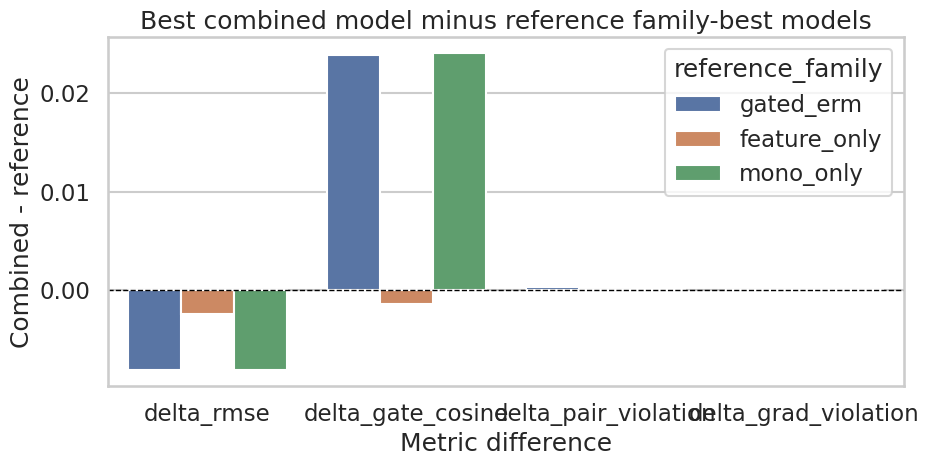

In [79]:
# Cell 11b - Direct family-best comparison for RQ3 (plot + save)

if len(family_best_comparison_df) == 0:
    print("No family-best comparison rows available.")
else:
    plot_df = family_best_comparison_df.copy()

    metrics_plot_df = pd.DataFrame(
        {
            "reference_family": plot_df["reference_family"],
            "delta_rmse": plot_df["delta_rmse_combined_minus_reference"],
            "delta_gate_cosine": plot_df["delta_gate_cosine_combined_minus_reference"],
            "delta_pair_violation": plot_df["delta_pair_violation_combined_minus_reference"],
            "delta_grad_violation": plot_df["delta_grad_violation_combined_minus_reference"],
        }
    )

    long_df = metrics_plot_df.melt(
        id_vars="reference_family",
        var_name="metric",
        value_name="delta_combined_minus_reference",
    )

    plt.figure(figsize=(10, 5))
    sns.barplot(
        data=long_df,
        x="metric",
        y="delta_combined_minus_reference",
        hue="reference_family",
    )
    plt.axhline(0.0, color="black", linestyle="--", linewidth=1)
    plt.title("Best combined model minus reference family-best models")
    plt.xlabel("Metric difference")
    plt.ylabel("Combined - reference")
    plt.tight_layout()
    plt.savefig("../docs/figures/ch5_rq3_family_best_comparison.pdf", dpi=300, bbox_inches="tight")
    plt.show()

In [80]:
# Cell 11c - Load cached selected family-best models when training is skipped

model_export_dir = COMBINED_DIR / "selected_models"

if RUN_TRAINING:
    print("RUN_TRAINING=True -> selected family-best models for the stored seed are already in memory.")

elif not LOAD_SELECTED_MODELS:
    print("LOAD_SELECTED_MODELS=False -> model-dependent qualitative cells will be skipped.")

else:
    manifest_path = model_export_dir / "manifest.csv"

    if manifest_path.exists():
        selected_model_manifest_df = pd.read_csv(manifest_path)

        for _, manifest_row in selected_model_manifest_df.iterrows():
            ckpt_path = Path(str(manifest_row["path"]))
            if not ckpt_path.is_absolute():
                # Manifest paths are stored relative to the manifest folder.
                ckpt_path = model_export_dir / ckpt_path
            if not ckpt_path.exists():
                print(f"[Missing checkpoint] {ckpt_path}")
                continue

            key = (
                float(manifest_row["lambda_feat"]),
                float(manifest_row["lambda_mono"]),
            )

            selected_model_store[key] = load_gated_model_checkpoint(
                ckpt_path,
                input_dim=len(feature_cols),
            )

        print(f"Loaded {len(selected_model_store)} selected models from: {manifest_path}")
        display(selected_model_manifest_df)

    else:
        print(f"No saved selected-model manifest found at {manifest_path}.")
        print("Model-dependent cells (gate profile / counterfactual plots) will be skipped.")

Loaded 4 selected models from: <project root>/results/combined_regularization/sweep_main/selected_models/manifest.csv


,model_family,lambda_feat,lambda_mono,seed,path
0,gated_erm,0.0,0.0,0,/...
1,feature_only,1.0,0.0,0,/...
2,mono_only,0.0,1.0,0,/...
3,combined,1.0,1.0,0,/...


In [81]:
# Cell 12 - Heatmaps over the lambda_feat x lambda_mono grid

def make_heat_pivot(df: pd.DataFrame, value_col: str) -> pd.DataFrame:
    out = (
        df.pivot(index="lambda_feat", columns="lambda_mono", values=value_col)
        .reindex(index=lambda_feat_values, columns=lambda_mono_values)
    )
    out.index.name = "lambda_feat"
    out.columns.name = "lambda_mono"
    return out

rmse_pivot = make_heat_pivot(agg_df, "test_rmse_mean")
gate_cos_pivot = make_heat_pivot(agg_df, "gate_cosine_mean")
pair_pivot = make_heat_pivot(agg_df, "test_pair_violation_macro_mean")
grad_pivot = make_heat_pivot(agg_df, "test_grad_violation_macro_mean")

print("Table: Test RMSE over (lambda_feat, lambda_mono)")
display(rmse_pivot.round(4))

print("Table: Gate cosine over (lambda_feat, lambda_mono)")
display(gate_cos_pivot.round(4))

print("Table: Test pairwise violation rate (macro) over (lambda_feat, lambda_mono)")
display(pair_pivot.round(4))

print("Table: Test gradient-sign violation rate (macro) over (lambda_feat, lambda_mono)")
display(grad_pivot.round(4))

Table: Test RMSE over (lambda_feat, lambda_mono)


lambda_mono,0.0,1.0,10.0,100.0,1000.0
lambda_feat,,,,,
0.0,2.3199,2.3200,2.3189,2.3194,2.3200
1.0,2.3142,2.3119,2.3199,2.3200,2.3262
10.0,2.2993,2.2966,2.2994,2.3075,2.3180
100.0,2.2803,2.2808,2.2843,2.2944,2.3106
1000.0,2.2739,2.2748,2.2790,2.2877,2.2978


Table: Gate cosine over (lambda_feat, lambda_mono)


lambda_mono,0.0,1.0,10.0,100.0,1000.0
lambda_feat,,,,,
0.0,0.8357,0.8355,0.8359,0.8361,0.8367
1.0,0.8609,0.8595,0.8585,0.8665,0.8606
10.0,0.9587,0.9592,0.9597,0.9604,0.9598
100.0,0.9908,0.9908,0.9907,0.9907,0.9905
1000.0,0.9919,0.9919,0.9919,0.9919,0.9919


Table: Test pairwise violation rate (macro) over (lambda_feat, lambda_mono)


lambda_mono,0.0,1.0,10.0,100.0,1000.0
lambda_feat,,,,,
0.0,0.0014,0.0015,0.0010,0.0006,0.0005
1.0,0.0017,0.0018,0.0012,0.0011,0.0005
10.0,0.0026,0.0025,0.0019,0.0009,0.0007
100.0,0.0032,0.0032,0.0022,0.0010,0.0008
1000.0,0.0035,0.0034,0.0023,0.0010,0.0008


Table: Test gradient-sign violation rate (macro) over (lambda_feat, lambda_mono)


lambda_mono,0.0,1.0,10.0,100.0,1000.0
lambda_feat,,,,,
0.0,0.0000,0.0000,0.0000,0.0,0.0
1.0,0.0000,0.0000,0.0000,0.0,0.0
10.0,0.0002,0.0000,0.0000,0.0,0.0
100.0,0.0015,0.0015,0.0000,0.0,0.0
1000.0,0.0044,0.0033,0.0011,0.0,0.0


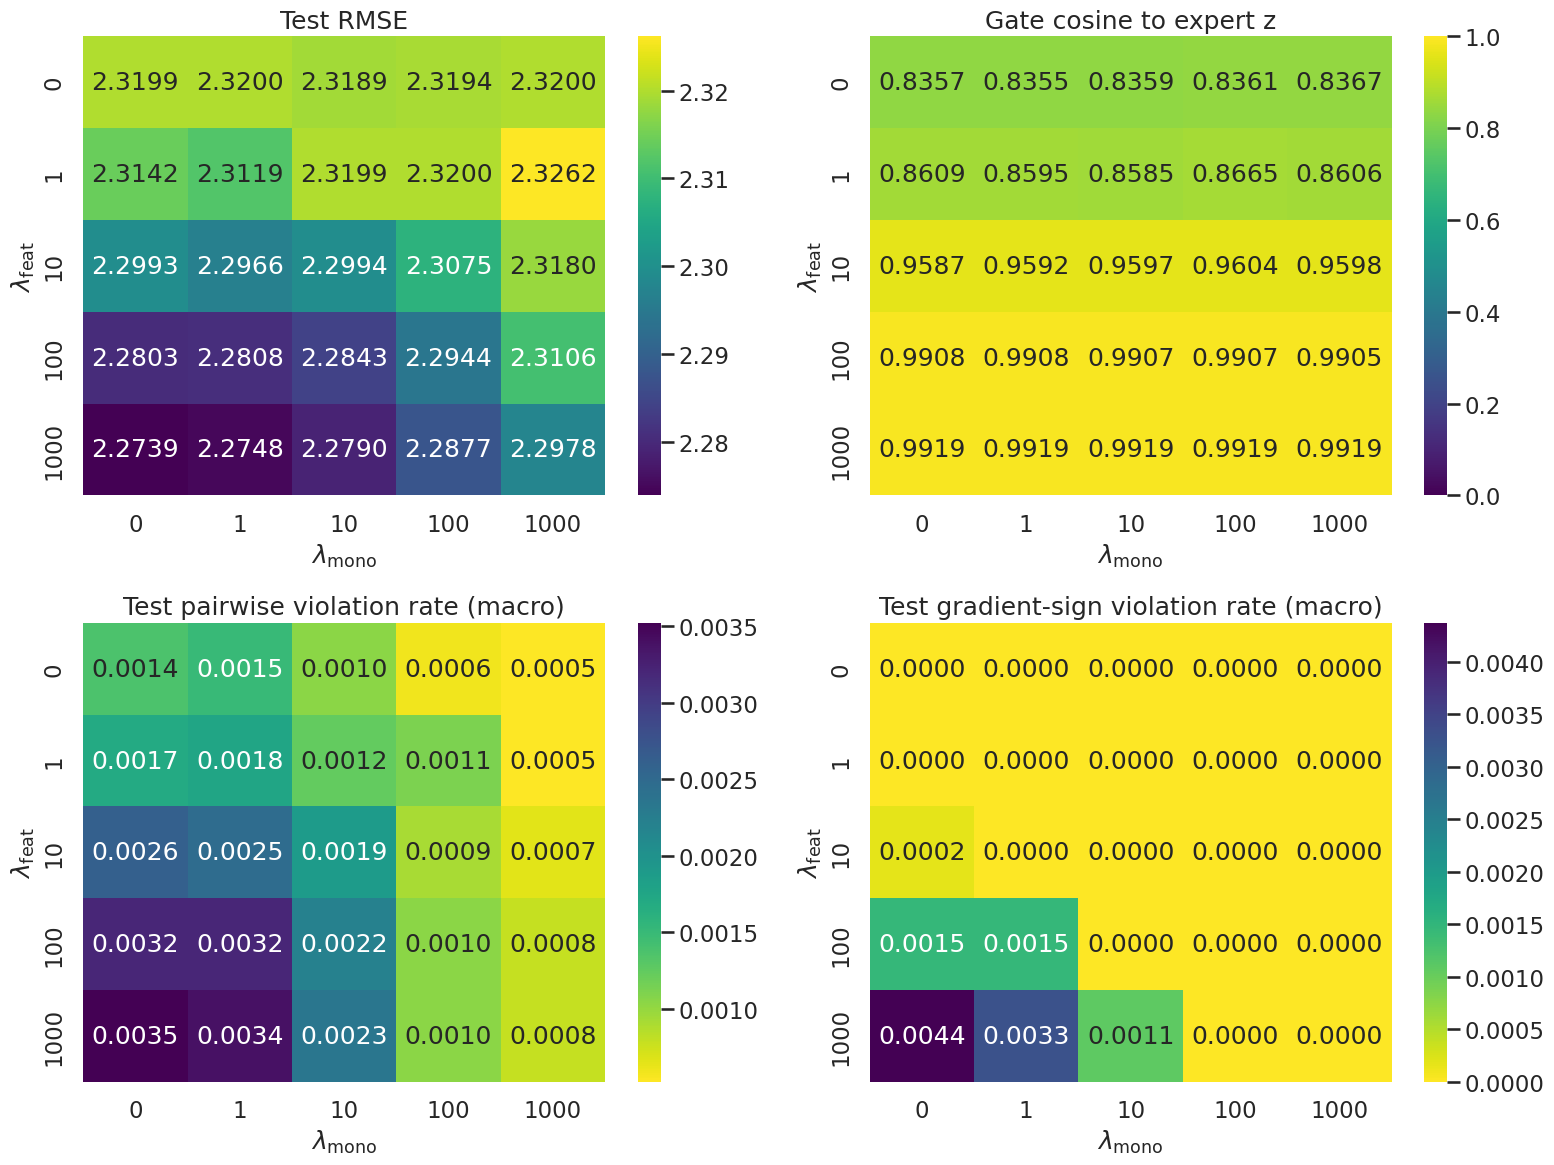

In [82]:
# Cell 12a - Heatmaps over the lambda_feat x lambda_mono grid

plot_rmse_pivot = rmse_pivot.copy()
plot_gate_cos_pivot = gate_cos_pivot.copy()
plot_pair_pivot = pair_pivot.copy()
plot_grad_pivot = grad_pivot.copy()

plot_rmse_pivot.index = [f"{x:g}" for x in plot_rmse_pivot.index]
plot_rmse_pivot.columns = [f"{x:g}" for x in plot_rmse_pivot.columns]

plot_gate_cos_pivot.index = [f"{x:g}" for x in plot_gate_cos_pivot.index]
plot_gate_cos_pivot.columns = [f"{x:g}" for x in plot_gate_cos_pivot.columns]

plot_pair_pivot.index = [f"{x:g}" for x in plot_pair_pivot.index]
plot_pair_pivot.columns = [f"{x:g}" for x in plot_pair_pivot.columns]

plot_grad_pivot.index = [f"{x:g}" for x in plot_grad_pivot.index]
plot_grad_pivot.columns = [f"{x:g}" for x in plot_grad_pivot.columns]

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

sns.heatmap(plot_rmse_pivot, annot=True, fmt=".4f", cmap="viridis", ax=axes[0, 0])
axes[0, 0].set_title("Test RMSE")
axes[0, 0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[0, 0].set_ylabel(r"$\lambda_{\mathrm{feat}}$")

sns.heatmap(
    plot_gate_cos_pivot,
    annot=True,
    fmt=".4f",
    cmap="viridis",
    vmin=0.0,
    vmax=1.0,
    ax=axes[0, 1],
)
axes[0, 1].set_title("Gate cosine to expert z")
axes[0, 1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[0, 1].set_ylabel(r"$\lambda_{\mathrm{feat}}$")

sns.heatmap(plot_pair_pivot, annot=True, fmt=".4f", cmap="viridis_r", ax=axes[1, 0])
axes[1, 0].set_title("Test pairwise violation rate (macro)")
axes[1, 0].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[1, 0].set_ylabel(r"$\lambda_{\mathrm{feat}}$")

sns.heatmap(plot_grad_pivot, annot=True, fmt=".4f", cmap="viridis_r", ax=axes[1, 1])
axes[1, 1].set_title("Test gradient-sign violation rate (macro)")
axes[1, 1].set_xlabel(r"$\lambda_{\mathrm{mono}}$")
axes[1, 1].set_ylabel(r"$\lambda_{\mathrm{feat}}$")

plt.tight_layout()
plt.savefig("../docs/figures/ch5_rq3_combined_heatmaps.pdf", dpi=300, bbox_inches="tight")
plt.savefig("../docs/figures/ch5_rq3_combined_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()

In [83]:
# Cell 13 - Per-feature monotonicity comparison for the family-best models

family_mono_rows = []
for family, row in family_best_rows.items():
    for feature in constrained_features:
        family_mono_rows.append(
            {
                "model_family": family,
                "feature": feature,
                "test_pair_violation_mean": row_float(row, f"test_pair_violation_{feature}_mean"),
                "test_grad_violation_mean": row_float(row, f"test_grad_violation_{feature}_mean"),
            }
        )

family_mono_df = pd.DataFrame(family_mono_rows)

print("Family-best per-feature monotonicity summary:")
display(family_mono_df.round(4))

Family-best per-feature monotonicity summary:


,model_family,feature,test_pair_violation_mean,test_grad_violation_mean
0,gated_erm,tavg,0.0000,0.0
1,gated_erm,tmax,0.0027,0.0
2,feature_only,tavg,0.0000,0.0
3,feature_only,tmax,0.0034,0.0
4,mono_only,tavg,0.0000,0.0
5,mono_only,tmax,0.0030,0.0
6,combined,tavg,0.0000,0.0
7,combined,tmax,0.0035,0.0


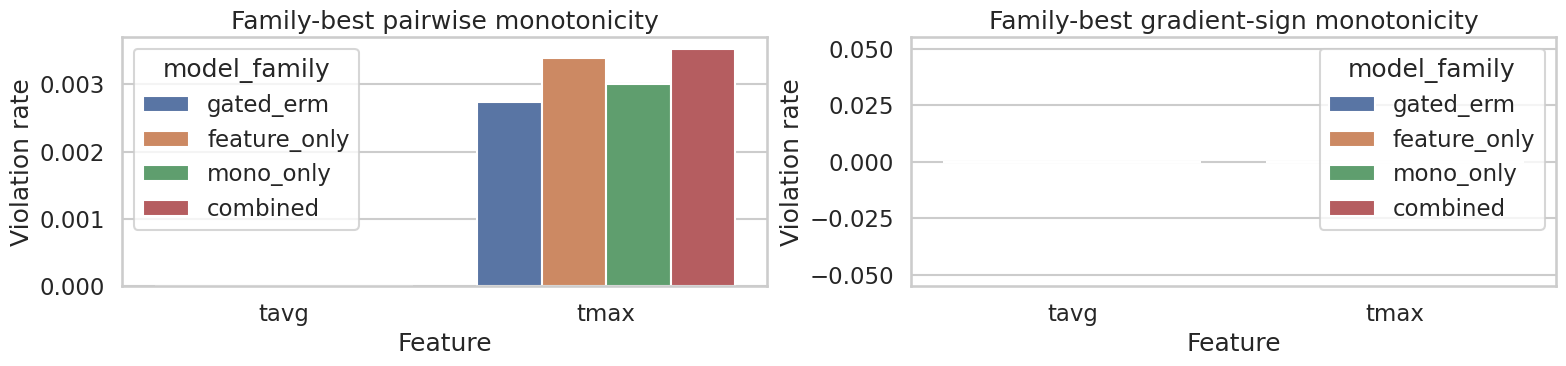

In [84]:
# Cell 13a - Per-feature monotonicity comparison for the family-best models (plot)

present_family_order = [f for f in family_order if f in family_mono_df["model_family"].unique()]

fig, axes = plt.subplots(1, 2, figsize=(16, 4), sharex=True)

sns.barplot(
    data=family_mono_df,
    x="feature",
    y="test_pair_violation_mean",
    hue="model_family",
    order=constrained_features,
    hue_order=present_family_order,
    ax=axes[0],
)
axes[0].set_title("Family-best pairwise monotonicity")
axes[0].set_xlabel("Feature")
axes[0].set_ylabel("Violation rate")

sns.barplot(
    data=family_mono_df,
    x="feature",
    y="test_grad_violation_mean",
    hue="model_family",
    order=constrained_features,
    hue_order=present_family_order,
    ax=axes[1],
)
axes[1].set_title("Family-best gradient-sign monotonicity")
axes[1].set_xlabel("Feature")
axes[1].set_ylabel("Violation rate")

plt.tight_layout()
plt.savefig("../docs/figures/ch5_rq3_family_best_monotonicity.pdf", dpi=300, bbox_inches="tight")
plt.show()

In [85]:
# Cell 14 - Optional contextual comparison with earlier notebooks
#
# Important:
# This is a contextual cross-notebook comparison, not a pure same-architecture ablation.
# - Notebook 03 baseline: plain MLP
# - Notebook 05 feature-only: gated model with feature prior only
# - Notebook 08 monotonicity-only: plain MLP with monotonicity prior
# - Current notebook: gated model with both priors available

external_rows: list[dict[str, float | str]] = []

if len(baseline_metrics_df) > 0:
    test_row = baseline_metrics_df.loc[baseline_metrics_df["split"] == "test"].iloc[0]
    external_rows.append(
        {
            "model": "plain MLP baseline (nb03)",
            "source": "03_baseline_training",
            "selection_rule": "saved test metrics",
            "lambda_feat": np.nan,
            "lambda_mono": np.nan,
            "test_rmse": float(test_row["rmse"]),
            "gate_cosine": np.nan,
            "test_pair_violation_macro": np.nan,
            "test_grad_violation_macro": np.nan,
        }
    )

if len(feature_main_summary_df) > 0:
    feat_sub = feature_main_summary_df.loc[feature_main_summary_df["lambda_feat"] > 0].copy()

    if len(feat_sub) > 0:
        if "E_star_gate" in feat_sub.columns:
            feat_sub = feat_sub.sort_values(["E_star_gate", "test_rmse_mean"], ascending=[False, True]).reset_index(drop=True)
            feat_rule = "max E_star_gate"
        else:
            feat_sub = feat_sub.sort_values(["test_rmse_mean"]).reset_index(drop=True)
            feat_rule = "min test_rmse_mean"

        feat_best = cast(pd.Series, feat_sub.iloc[0])

        external_rows.append(
            {
                "model": "best feature-only (nb05)",
                "source": "05_feature_importance_sweep",
                "selection_rule": feat_rule,
                "lambda_feat": row_float(feat_best, "lambda_feat"),
                "lambda_mono": 0.0,
                "test_rmse": row_float(feat_best, "test_rmse_mean"),
                "gate_cosine": row_float(feat_best, "gate_cosine_mean"),
                "test_pair_violation_macro": np.nan,
                "test_grad_violation_macro": np.nan,
            }
        )

if len(mono_main_summary_df) > 0:
    mono_sub = mono_main_summary_df.loc[mono_main_summary_df["lambda_mono"] > 0].copy()

    if len(mono_sub) > 0:
        mono_sub = mono_sub.sort_values(["best_val_total_mean", "test_rmse_mean"]).reset_index(drop=True)
        mono_best = cast(pd.Series, mono_sub.iloc[0])

        external_rows.append(
            {
                "model": "best monotonic-only (nb08)",
                "source": "08_rq2_monotonicity_training",
                "selection_rule": "min best_val_total_mean",
                "lambda_feat": 0.0,
                "lambda_mono": row_float(mono_best, "lambda_mono"),
                "test_rmse": row_float(mono_best, "test_rmse_mean"),
                "gate_cosine": np.nan,
                "test_pair_violation_macro": row_float(mono_best, "test_pair_violation_macro_mean"),
                "test_grad_violation_macro": row_float(mono_best, "test_grad_violation_macro_mean"),
            }
        )

if "gated_erm" in family_best_rows:
    row = family_best_rows["gated_erm"]
    external_rows.append(
        {
            "model": "best gated ERM (current)",
            "source": "10_rq3_combined_regularization",
            "selection_rule": "current family baseline",
            "lambda_feat": row_float(row, "lambda_feat"),
            "lambda_mono": row_float(row, "lambda_mono"),
            "test_rmse": row_float(row, "test_rmse_mean"),
            "gate_cosine": row_float(row, "gate_cosine_mean"),
            "test_pair_violation_macro": row_float(row, "test_pair_violation_macro_mean"),
            "test_grad_violation_macro": row_float(row, "test_grad_violation_macro_mean"),
        }
    )

if "combined" in family_best_rows:
    row = family_best_rows["combined"]
    external_rows.append(
        {
            "model": "best combined (current)",
            "source": "10_rq3_combined_regularization",
            "selection_rule": "min best_val_total_mean within combined family",
            "lambda_feat": row_float(row, "lambda_feat"),
            "lambda_mono": row_float(row, "lambda_mono"),
            "test_rmse": row_float(row, "test_rmse_mean"),
            "gate_cosine": row_float(row, "gate_cosine_mean"),
            "test_pair_violation_macro": row_float(row, "test_pair_violation_macro_mean"),
            "test_grad_violation_macro": row_float(row, "test_grad_violation_macro_mean"),
        }
    )

external_context_df = pd.DataFrame(external_rows)

if len(external_context_df) == 0:
    print("No earlier summary files were found, so the contextual comparison table was skipped.")
else:
    print("Contextual cross-notebook comparison:")
    display(external_context_df.round(4))

Contextual cross-notebook comparison:


,model,source,selection_rule,lambda_feat,lambda_mono,test_rmse,gate_cosine,test_pair_violation_macro,test_grad_violation_macro
0,plain MLP baseline (nb03),03_baseline_training,saved test metrics,NaN,NaN,2.3038,NaN,NaN,NaN
1,best feature-only (nb05),05_feature_importance_sweep,min test_rmse_mean,1000.0,0.0,2.2895,0.9839,NaN,NaN
2,best monotonic-only (nb08),08_rq2_monotonicity_training,min best_val_total_mean,0.0,1.0,2.3126,NaN,0.0016,0.0
3,best gated ERM (current),10_rq3_combined_regularization,current family baseline,0.0,0.0,2.3199,0.8357,0.0014,0.0
4,best combined (current),10_rq3_combined_regularization,min best_val_total_mean within combined family,1.0,1.0,2.3119,0.8595,0.0018,0.0


In [86]:
# Cell 15 - Gate profile comparison: expert z vs family-best selected-seed models

gate_profile_rows: list[dict[str, float | str]] = []

target_row: dict[str, float | str] = {
    "model": "expert_z",
    "model_family": "target",
    "lambda_feat": np.nan,
    "lambda_mono": np.nan,
}
for name, value in zip(feature_cols, z_np):
    target_row[name] = float(value)
gate_profile_rows.append(target_row)

n_loaded_family_models = 0

for family in family_order:
    if family not in best_keys_by_family:
        continue

    key = best_keys_by_family[family]
    if key not in selected_model_store:
        print(f"[Skip] Missing stored model for family={family}, key={key}")
        continue

    model = selected_model_store[key]
    g_final = model.g.detach().cpu().numpy().astype(np.float64)

    row: dict[str, float | str] = {
        "model": family,
        "model_family": family,
        "lambda_feat": float(key[0]),
        "lambda_mono": float(key[1]),
    }
    for name, value in zip(feature_cols, g_final):
        row[name] = float(value)

    gate_profile_rows.append(row)
    n_loaded_family_models += 1

gate_profile_df = pd.DataFrame(gate_profile_rows)

if n_loaded_family_models == 0:
    print("No loaded selected models available for gate-profile comparison.")
else:
    print("Gate profile table:")

display(gate_profile_df.round(4))

Gate profile table:


,model,model_family,lambda_feat,lambda_mono,tmin,tavg,tmax,prcp,dayofyear_sin,dayofyear_cos,rand_noise
0,expert_z,target,NaN,NaN,0.7000,1.0000,1.0000,0.4000,0.3000,0.3000,0.0000
1,gated_erm,gated_erm,0.0,0.0,0.7496,0.7658,0.7557,0.7656,0.7503,0.7601,0.7296
2,feature_only,feature_only,1.0,0.0,0.7509,0.7770,0.7571,0.7368,0.7029,0.7438,0.6316
3,mono_only,mono_only,0.0,1.0,0.7494,0.7656,0.7556,0.7667,0.7503,0.7603,0.7293
4,combined,combined,1.0,1.0,0.7506,0.7767,0.7572,0.7355,0.7029,0.7441,0.6309


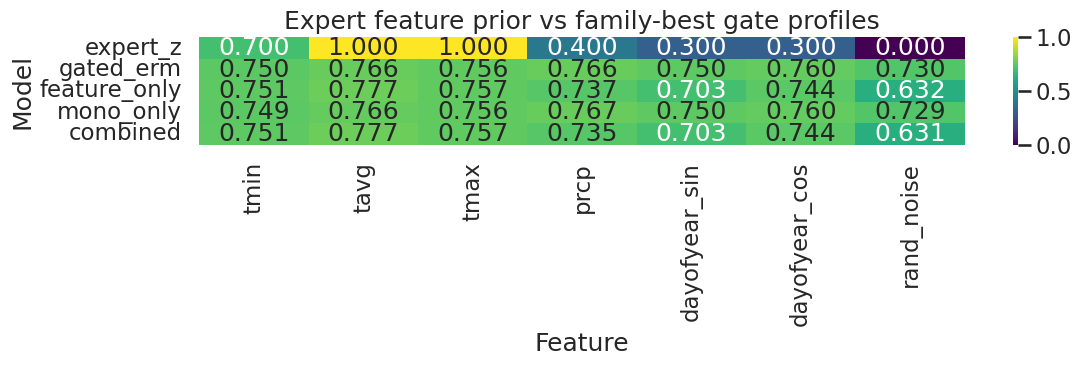

In [87]:
# Cell 15a - Gate profile comparison: expert z vs family-best selected-seed models (heatmap)

if len(gate_profile_df) <= 1:
    print("Skipping gate-profile heatmap because no loaded selected models are available.")
else:
    gate_profile_heat = gate_profile_df.set_index("model")[feature_cols].copy()

    plt.figure(figsize=(12, max(4, 0.7 * len(gate_profile_heat))))
    sns.heatmap(gate_profile_heat, annot=True, fmt=".3f", cmap="viridis", vmin=0.0, vmax=1.0)
    plt.title("Expert feature prior vs family-best gate profiles")
    plt.xlabel("Feature")
    plt.ylabel("Model")
    plt.tight_layout()
    plt.savefig("../docs/figures/ch5_rq3_gate_profile_heatmap.pdf", dpi=300, bbox_inches="tight")
    plt.show()

In [88]:
# Cell 16 - Save selected family-best model checkpoints for the stored seed

model_export_dir = COMBINED_DIR / "selected_models"
model_export_dir.mkdir(parents=True, exist_ok=True)

if RUN_TRAINING:
    selected_model_records: list[dict[str, float | str]] = []

    for family, key in best_keys_by_family.items():
        if key not in selected_model_store:
            continue

        model_path = model_export_dir / (
            f"{family}"
            f"__lambda_feat_{key[0]:g}"
            f"__lambda_mono_{key[1]:g}"
            f"__seed_{selected_seed_for_store}.pt"
        )

        torch.save(selected_model_store[key].state_dict(), model_path)

        selected_model_records.append(
            {
                "model_family": family,
                "lambda_feat": float(key[0]),
                "lambda_mono": float(key[1]),
                "seed": int(selected_seed_for_store),
                "path": model_path.name,
            }
        )

    selected_model_manifest_df = pd.DataFrame(selected_model_records)
    selected_model_manifest_df.to_csv(model_export_dir / "manifest.csv", index=False)

    with open(model_export_dir / "manifest.json", "w") as fh:
        json.dump(selected_model_records, fh, indent=2)

    print("Saved selected family-best model checkpoints to:", model_export_dir)
    display(selected_model_manifest_df)

else:
    manifest_path = model_export_dir / "manifest.csv"
    if manifest_path.exists():
        selected_model_manifest_df = pd.read_csv(manifest_path)
        print("RUN_TRAINING=False, so existing selected model manifest was loaded instead of being rewritten.")
        display(selected_model_manifest_df)
    else:
        print("RUN_TRAINING=False and no existing selected model manifest was found.")

RUN_TRAINING=False, so existing selected model manifest was loaded instead of being rewritten.


,model_family,lambda_feat,lambda_mono,seed,path
0,gated_erm,0.0,0.0,0,/...
1,feature_only,1.0,0.0,0,/...
2,mono_only,0.0,1.0,0,/...
3,combined,1.0,1.0,0,/...


In [89]:
# Cell 17 - Qualitative counterfactual comparison on representative test rows

rep_rows = pd.DataFrame()
plot_families = []
models_for_plots = {}
plot_labels = {}

available_plot_families = [
    family
    for family in family_order
    if family in best_keys_by_family and best_keys_by_family[family] in selected_model_store
]

if "gated_erm" not in available_plot_families:
    print("Skipping qualitative counterfactual comparison because no stored gated_erm checkpoint is available.")
else:
    plot_families = available_plot_families

    models_for_plots = {
        family: copy.deepcopy(selected_model_store[best_keys_by_family[family]]).to(device)
        for family in plot_families
    }

    for family in plot_families:
        models_for_plots[family].eval()

    plot_labels = {}
    for family in plot_families:
        lam_feat, lam_mono = best_keys_by_family[family]
        if family == "gated_erm":
            plot_labels[family] = "gated ERM"
        elif family == "feature_only":
            plot_labels[family] = f"feature only (λ_feat={lam_feat:g})"
        elif family == "mono_only":
            plot_labels[family] = f"mono only (λ_mono={lam_mono:g})"
        else:
            plot_labels[family] = f"combined (λ_feat={lam_feat:g}, λ_mono={lam_mono:g})"

    qual_test_df = data.test_df.copy().reset_index(drop=True)
    qual_test_df["row_id"] = np.arange(len(qual_test_df))
    qual_test_df["y_true"] = data.y_test.astype(float)
    qual_test_df["baseline_pred"] = predict_numpy(
        models_for_plots["gated_erm"],
        data.X_test,
        device=device,
        use_gate=True,
    )

    for j, name in enumerate(feature_cols):
        qual_test_df[f"{name}__scaled"] = data.X_test[:, j]

    rep_rows = select_representative_rows(
        qual_test_df,
        col="y_true",
        quantiles=(0.1, 0.5, 0.9),
    )

In [90]:
# Cell 17a - Representative test rows (table for qualitative plots)

if len(rep_rows) == 0:
    print("Representative test rows are unavailable because the qualitative models were not loaded.")
else:
    print("Representative test rows:")
    display(
        rep_rows[
            ["row_id", "datetime", "y_true", "baseline_pred", "tmin", "tavg", "tmax", "prcp"]
        ].round(3)
    )

Representative test rows:


/tmp/ipykernel_296355/1359463529.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ].round(3)


,row_id,datetime,y_true,baseline_pred,tmin,tavg,tmax,prcp
221,221,2025-02-06 02:00:00,0.3,1.214,-0.2,0.8,1.7,0.0
461,461,2025-10-04 03:00:00,10.7,10.054,3.2,7.2,10.0,0.6
397,397,2025-08-01 03:00:00,23.2,23.364,17.4,20.8,25.4,10.3


In [91]:
# Cell 17b - Counterfactual summary table for the qualitative plots

def summarize_counterfactual_curve(cf_df: pd.DataFrame, sign: int = +1, tol: float = 1e-8) -> dict[str, float | bool]:
    x = cf_df["feature_value_orig"].to_numpy(dtype=float)
    y = cf_df["prediction"].to_numpy(dtype=float)

    signed_steps = sign * np.diff(y)

    return {
        "grid_low": float(x[0]),
        "grid_mid": float(x[len(x) // 2]),
        "grid_high": float(x[-1]),
        "pred_low": float(y[0]),
        "pred_mid": float(y[len(y) // 2]),
        "pred_high": float(y[-1]),
        "delta_high_minus_low": float(y[-1] - y[0]),
        "monotone_on_grid": bool(np.all(signed_steps >= -tol)),
        "n_wrong_steps": int(np.sum(signed_steps < -tol)),
    }

counterfactual_summary_df = pd.DataFrame()

if len(rep_rows) == 0 or len(plot_families) == 0:
    print("Skipping counterfactual summary because qualitative models are unavailable.")
else:
    counterfactual_summary_rows: list[dict[str, float | str | bool]] = []

    for feature_name in constrained_features:
        grid_orig = np.linspace(
            data.train_df[feature_name].quantile(0.05),
            data.train_df[feature_name].quantile(0.95),
            21,
        )

        for _, base_row in rep_rows.iterrows():
            for family in plot_families:
                cf_df = make_counterfactual_sweep_df(
                    models_for_plots[family],
                    base_row=base_row,
                    feature_name=feature_name,
                    grid_orig=grid_orig,
                    feature_cols=feature_cols,
                    scaler=data.scaler,
                    device=device,
                    use_gate=True,
                )

                row: dict[str, float | str | bool] = {
                    "model_family": family,
                    "model_label": plot_labels[family],
                    "feature": feature_name,
                    "row_id": int(base_row["row_id"]),
                    "y_true": float(base_row["y_true"]),
                }
                row.update(summarize_counterfactual_curve(cf_df, sign=int(sign_dict[feature_name])))
                counterfactual_summary_rows.append(row)

    counterfactual_summary_df = (
        pd.DataFrame(counterfactual_summary_rows)
        .sort_values(["feature", "row_id", "model_family"])
        .reset_index(drop=True)
    )

    print("Counterfactual summary table:")
    display(counterfactual_summary_df.round(4))

Counterfactual summary table:


,model_family,model_label,feature,row_id,y_true,grid_low,grid_mid,grid_high,pred_low,pred_mid,pred_high,delta_high_minus_low,monotone_on_grid,n_wrong_steps
0,combined,"combined (λ_feat=1, λ_mono=1)",tavg,221,0.3,-7.800,5.8000,19.4,-4.7843,4.7878,12.0259,16.8102,True,0
1,feature_only,feature only (λ_feat=1),tavg,221,0.3,-7.800,5.8000,19.4,-4.8096,4.7839,12.1190,16.9286,True,0
2,gated_erm,gated ERM,tavg,221,0.3,-7.800,5.8000,19.4,-3.5499,4.2109,10.6864,14.2364,True,0
3,mono_only,mono only (λ_mono=1),tavg,221,0.3,-7.800,5.8000,19.4,-3.5578,4.2137,10.6054,14.1633,True,0
4,combined,"combined (λ_feat=1, λ_mono=1)",tavg,397,23.2,-7.800,5.8000,19.4,11.5302,17.4485,22.9874,11.4573,True,0
5,feature_only,feature only (λ_feat=1),tavg,397,23.2,-7.800,5.8000,19.4,11.7213,17.4120,22.9452,11.2240,True,0
6,gated_erm,gated ERM,tavg,397,23.2,-7.800,5.8000,19.4,13.5267,17.9742,22.7915,9.2648,True,0
7,mono_only,mono only (λ_mono=1),tavg,397,23.2,-7.800,5.8000,19.4,13.4802,18.0181,22.8095,9.3293,True,0
8,combined,"combined (λ_feat=1, λ_mono=1)",tavg,461,10.7,-7.800,5.8000,19.4,-0.4694,9.3427,17.3281,17.7974,True,0
9,feature_only,feature only (λ_feat=1),tavg,461,10.7,-7.800,5.8000,19.4,-0.4572,9.3735,17.3263,17.7835,True,0


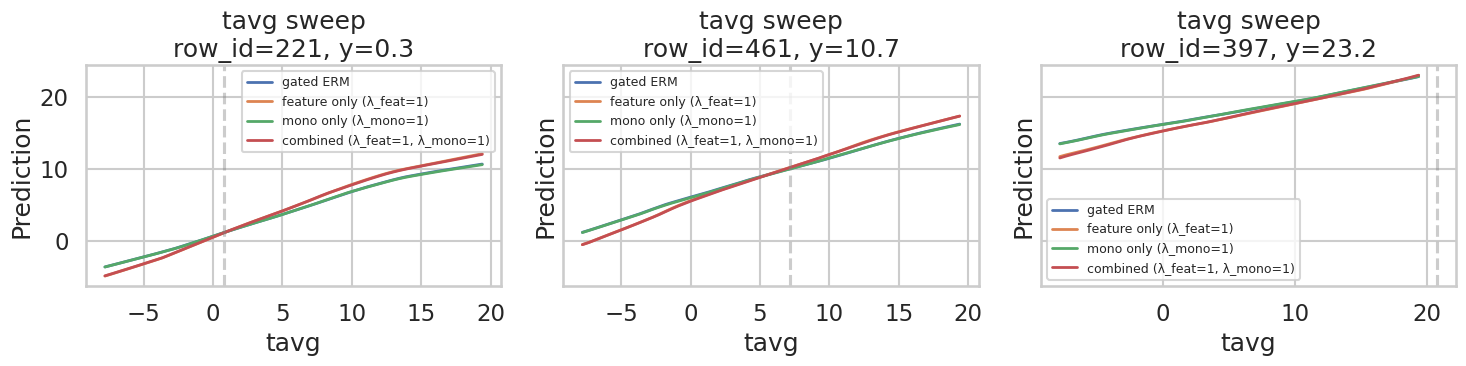

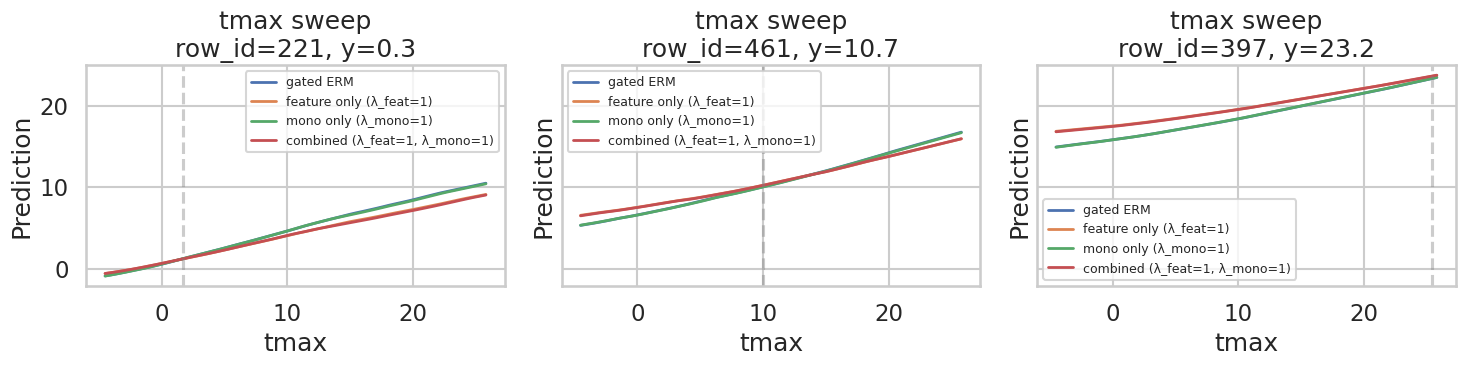

In [92]:
# Cell 17c - Qualitative counterfactual comparison on representative test rows (plots)

if len(rep_rows) == 0 or len(plot_families) == 0:
    print("Skipping qualitative counterfactual plots because qualitative models are unavailable.")
else:
    for feature_name in constrained_features:
        grid_orig = np.linspace(
            data.train_df[feature_name].quantile(0.05),
            data.train_df[feature_name].quantile(0.95),
            60,
        )

        fig, axes = plt.subplots(1, len(rep_rows), figsize=(5 * len(rep_rows), 4), sharey=True)
        if len(rep_rows) == 1:
            axes = [axes]

        for ax, (_, base_row) in zip(axes, rep_rows.iterrows()):
            for family in plot_families:
                cf_df = make_counterfactual_sweep_df(
                    models_for_plots[family],
                    base_row=base_row,
                    feature_name=feature_name,
                    grid_orig=grid_orig,
                    feature_cols=feature_cols,
                    scaler=data.scaler,
                    device=device,
                    use_gate=True,
                )

                ax.plot(
                    cf_df["feature_value_orig"],
                    cf_df["prediction"],
                    label=plot_labels[family],
                    linewidth=2,
                )

            ax.axvline(float(base_row[feature_name]), color="gray", linestyle="--", alpha=0.4)
            ax.set_title(
                f"{feature_name} sweep\n"
                f"row_id={int(base_row['row_id'])}, y={base_row['y_true']:.1f}"
            )
            ax.set_xlabel(feature_name)
            ax.set_ylabel("Prediction")
            ax.legend(fontsize=9)

        plt.tight_layout()
        plt.savefig(
            f"../docs/figures/ch5_rq3_counterfactual_{feature_name}.pdf",
            dpi=300,
            bbox_inches="tight",
        )
        plt.show()

## Interpretation guide

When reading the results:

- lower **test RMSE** is better for predictive performance,
- higher **gate cosine similarity** is better for alignment to the expert feature prior,
- lower **pairwise violation rate** is better for monotonic alignment on the saved local pairs,
- lower **gradient-sign violation rate** is better for local differential monotonicity,
- lower **best validation total** indicates a better compromise under the combined training objective.

A useful RQ3 result is not necessarily that the combined model beats every
single-prior model on every metric.

A positive outcome would be, for example:

- similar RMSE to the better single-prior models,
- clearly better gate alignment than the mono-only model,
- clearly better monotonicity than the feature-only model,
- and a plausible combined compromise overall.

Because notebook 08 showed that the baseline was already fairly monotone on the
selected features, the main value of combined regularization may be
**compatibility and controlled trade-offs** rather than dramatic monotonicity gains.

In [93]:
# Cell 18 - Save compact thesis-use summaries

thesis_dir = RESULTS_ROOT / "combined_regularization" / "thesis_exports"
thesis_dir.mkdir(parents=True, exist_ok=True)

summary_table.to_csv(thesis_dir / "combined_summary_table.csv", index=False)
family_best_df.to_csv(thesis_dir / "family_best_summary.csv", index=False)
family_mono_df.to_csv(thesis_dir / "family_best_per_feature_mono.csv", index=False)
gate_profile_df.to_csv(thesis_dir / "gate_profile_comparison.csv", index=False)

if "counterfactual_summary_df" in globals() and len(counterfactual_summary_df) > 0:
    counterfactual_summary_df.to_csv(thesis_dir / "counterfactual_summary.csv", index=False)

if len(external_context_df) > 0:
    external_context_df.to_csv(thesis_dir / "contextual_cross_notebook_comparison.csv", index=False)

if len(selected_model_manifest_df) > 0:
    selected_model_manifest_df.to_csv(thesis_dir / "selected_model_manifest.csv", index=False)

print("Saved compact thesis-use summaries to:", thesis_dir)

Saved compact thesis-use summaries to: <project root>/results/combined_regularization/thesis_exports
